# DAY3 과제 06 : 와인 데이터로 두 집단 평균 비교

와인 종류 0과 1의 평균 알코올 함량이 다른지, 표본을 직접 뽑아 Welch t검정으로 확인한다. 문제 아래 코드 셀에 직접 코드를 작성하고 실행한다.

데이터 : scikit-learn 내장 데이터 `load_wine` (원자료 : UCI Wine 데이터셋)
이탈리아의 같은 지역에서 재배된 세 품종 와인 178개 시료의 화학 분석 결과다. 파일을 내려받지 않고 아래 제공 코드로 바로 불러온다.

| 열 | 뜻 |
|---|---|
| alcohol | 알코올 함량 |
| target | 와인 종류 (0, 1, 2). 숫자는 종류를 구분하는 코드이며 크기에 뜻이 없다 |

공통 조건 : 유의수준 α = 0.05, 양측검정.

공식 문서 : [sklearn.datasets.load_wine](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html)

**답을 쓰는 형식**

- 가설 : `귀무가설(H₀): 한글 문장. (기호)` / `대립가설(H₁): 한글 문장. (기호)`
- 결론 : `통계적 결론 : p = ___ ___ 0.05 이므로 귀무가설을 ___.` / `사실적 결론 : ~ 통계적 근거가 ___ (관측값).`
- 숫자는 `print("이름:", round(값, 4))`처럼 출력한다. p값이 아주 작아 `9.0e-06`처럼 나오면 결론에는 `p < 0.001`로 쓴다.

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
# 제공 코드 : 와인 데이터를 불러온다
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)      # as_frame=True : 판다스 데이터프레임으로 받는다
df = wine.frame

data = df[["alcohol", "target"]].copy()
data.head()

,alcohol,target
0,14.23,0
1,13.20,0
2,13.16,0
3,14.37,0
4,13.24,0


### 1. 데이터 확인

와인 종류(`target`)별 시료 수와 `alcohol`의 결측 수를 구하시오.

In [ ]:
# 힌트 : data["열"].value_counts(), data["열"].isna().sum()




### 2. 표본 추출

와인 종류 0과 1에서 `alcohol`을 각각 25개씩 비복원으로 뽑아(둘 다 `random_state=42`) `group0`, `group1`로 저장하고, 집단별 평균과 표준편차를 구하시오.

In [ ]:
# 힌트 : data.loc[data["target"] == 0, "alcohol"].sample(n=25, replace=False, random_state=42)




### 3. 정규성 확인

귀무가설(H₀): 각 종류의 알코올 함량은 정규분포를 따른다.
대립가설(H₁): 각 종류의 알코올 함량은 정규분포를 따르지 않는다.

두 집단의 히스토그램을 나란히 그리고, 집단별 Shapiro-Wilk p값을 구해 Welch t검정을 쓸 수 있는지 판단하시오.

In [ ]:
# 힌트 : fig, axes = plt.subplots(1, 2, figsize=(12, 4)), axes[0].hist(...), stats.shapiro(데이터).pvalue




### 4. Welch t검정

두 와인 종류의 모집단 평균 알코올 함량이 다른지 검정한다. 귀무가설과 대립가설을 쓰고(μ₁ : 종류 0의 모평균, μ₂ : 종류 1의 모평균), Welch t검정의 t, p값, 자유도를 구하시오.

p값은 `round` 없이 그대로 출력한다.

In [ ]:
# 귀무가설(H₀):
# 대립가설(H₁):

# 힌트 : stats.ttest_ind(group0, group1, equal_var=False)




### 5. 평균 차이와 95% 신뢰구간

평균 차이(종류 0 − 종류 1)와 모평균 차이의 95% 신뢰구간을 구하시오.

In [ ]:
# 힌트 : 4번 검정 결과.confidence_interval(confidence_level=0.95)




### 6. 결론

아래 결론 문장의 빈칸을 채우시오.

통계적 결론 : p ___ 0.001 < 0.05 이므로 귀무가설을 ___________.
사실적 결론 : 와인 종류 0과 1의 모집단 평균 알코올 함량은 다르다고 볼 통계적 근거가 ______. 표본에서 종류 0의 평균 알코올 함량이 종류 1보다 ______ 높았다 (95% 신뢰구간 ______ ~ ______, 각 25개).

In [ ]:
# 빈칸을 채워 아래에 적는다




## 확인문제

앞의 결과를 보고 답을 1~2문장으로 적으시오.

### 확인 1. 4번 p값이 `6.7e-13`처럼 출력되었다. `round(p값, 4)`로 출력하면 무엇이 보이며, 결론에는 어떻게 쓰는가?

**답 :**

### 확인 2. 이 과제에서 대응표본 t검정이 아니라 독립표본 검정(Welch)을 쓰는 이유는 무엇인가?

**답 :**

## 문제 정답

### 1. 데이터 확인

In [ ]:
print(data["target"].value_counts().sort_index())
print("alcohol 결측:", data["alcohol"].isna().sum())

# 종류 0 : 59개, 종류 1 : 71개, 종류 2 : 48개. 결측 0건

target
0    59
1    71
2    48
Name: count, dtype: int64
alcohol 결측: 0


### 2. 표본 추출

In [ ]:
group0 = data.loc[data["target"] == 0, "alcohol"].sample(n=25, replace=False, random_state=42)
group1 = data.loc[data["target"] == 1, "alcohol"].sample(n=25, replace=False, random_state=42)

print("종류 0 평균:", round(group0.mean(), 4), "/ 표준편차:", round(group0.std(), 4))
print("종류 1 평균:", round(group1.mean(), 4), "/ 표준편차:", round(group1.std(), 4))

# 종류 0 평균 13.7808, 표준편차 0.4983 / 종류 1 평균 12.304, 표준편차 0.5692

종류 0 평균: 13.7808 / 표준편차: 0.4983
종류 1 평균: 12.304 / 표준편차: 0.5692


### 3. 정규성 확인

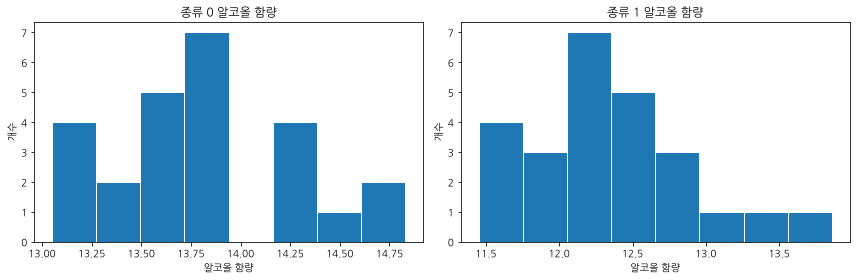

종류 0 Shapiro-Wilk p값: 0.3428
종류 1 Shapiro-Wilk p값: 0.1727


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(group0, bins=8, edgecolor="white")
axes[0].set(title="종류 0 알코올 함량", xlabel="알코올 함량", ylabel="개수")
axes[1].hist(group1, bins=8, edgecolor="white")
axes[1].set(title="종류 1 알코올 함량", xlabel="알코올 함량", ylabel="개수")
plt.tight_layout()
plt.show()

print("종류 0 Shapiro-Wilk p값:", round(stats.shapiro(group0).pvalue, 4))
print("종류 1 Shapiro-Wilk p값:", round(stats.shapiro(group1).pvalue, 4))

# 종류 0 p = 0.3428, 종류 1 p = 0.1727 → 둘 다 0.05 이상이고 그림에서도 한쪽으로 크게 치우치지 않으므로 Welch t검정을 쓴다

### 4. Welch t검정

In [ ]:
# 귀무가설(H₀): 와인 종류 0과 1의 모집단 평균 알코올 함량은 같다. (μ₁ = μ₂)
# 대립가설(H₁): 와인 종류 0과 1의 모집단 평균 알코올 함량은 다르다. (μ₁ ≠ μ₂)

wine_result = stats.ttest_ind(group0, group1, equal_var=False)
print("t:", round(wine_result.statistic, 3), "/ 자유도:", round(wine_result.df, 2))
print("p값:", wine_result.pvalue)

# t = 9.761, 자유도 47.17, p = 6.7e-13 (p < 0.001)

t: 9.761 / 자유도: 47.17
p값: 6.688224629209822e-13


### 5. 평균 차이와 95% 신뢰구간

In [ ]:
print("평균 차이(종류 0 − 종류 1):", round(group0.mean() - group1.mean(), 4))
wine_ci = wine_result.confidence_interval(confidence_level=0.95)
print("95% 신뢰구간:", round(wine_ci.low, 4), "~", round(wine_ci.high, 4))

# 평균 차이 1.4768, 95% 신뢰구간 1.1725 ~ 1.7811 → 0 이 구간 밖에 있다

평균 차이(종류 0 − 종류 1): 1.4768
95% 신뢰구간: 1.1725 ~ 1.7811


### 6. 결론

In [ ]:
# 통계적 결론 : p < 0.001 < 0.05 이므로 귀무가설을 기각한다.
# 사실적 결론 : 와인 종류 0과 1의 모집단 평균 알코올 함량은 다르다고 볼 통계적 근거가 있다. 표본에서 종류 0의 평균 알코올 함량이 종류 1보다 1.4768 높았다 (95% 신뢰구간 1.1725 ~ 1.7811, 각 25개).